<a href="https://colab.research.google.com/github/tannu550/Toxic_comment_classification/blob/main/Mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Model & prototype

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import pandas as pd
df = pd.read_csv("/content/tripadvisor_hotel_reviews.csv", engine="python", on_bad_lines='skip')

In [ ]:
df.head()

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


In [ ]:
print(df.info())
print(df.columns)
print(df['Rating'].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964 entries, 0 to 2963
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  2964 non-null   object
 1   Rating  2964 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 46.4+ KB
None
Index(['Review', 'Rating'], dtype='object')
Rating
5    1170
4     865
3     357
2     299
1     273
Name: count, dtype: int64


In [ ]:
df['Review'] = df['Review'].fillna("")
df['review_len'] = df['Review'].str.len()
print(df['review_len'].describe())

count    2964.000000
mean      702.216937
std       620.217395
min        44.000000
25%       335.000000
50%       535.500000
75%       851.500000
max      8953.000000
Name: review_len, dtype: float64


In [ ]:
def map_sentiment(r):
    if r <= 2: return 0
    elif r == 3: return 1
    else: return 2

df['sentiment'] = df['Rating'].apply(map_sentiment)
df['sentiment'].value_counts()


,count
sentiment,
2,2035
0,572
1,357


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['Review'], df['sentiment'],
    test_size=0.2, stratify=df['sentiment'], random_state=42
)

In [ ]:
#Vectorize with TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2), stop_words="english")
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

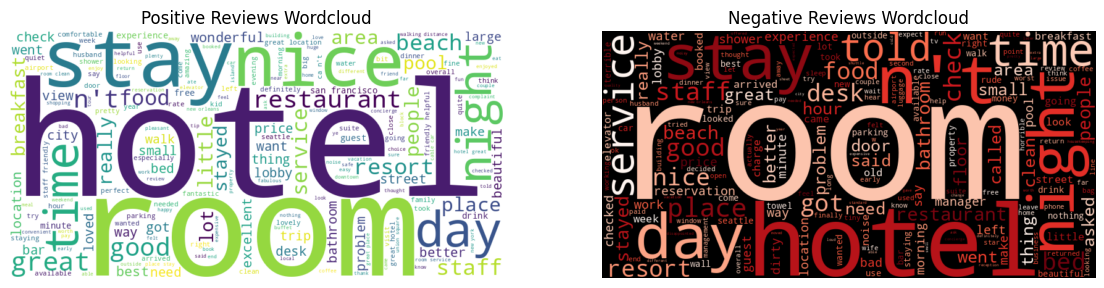

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

positive_text = " ".join(df[df["sentiment"] == 2]["Review"])
wordcloud_pos = WordCloud(width=800, height=400, background_color="white").generate(positive_text)

negative_text = " ".join(df[df["sentiment"] == 0]["Review"])
wordcloud_neg = WordCloud(width=800, height=400, background_color="black", colormap="Reds").generate(negative_text)


plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
plt.imshow(wordcloud_pos, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Reviews Wordcloud")

plt.subplot(1,2,2)
plt.imshow(wordcloud_neg, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Reviews Wordcloud")
plt.show()

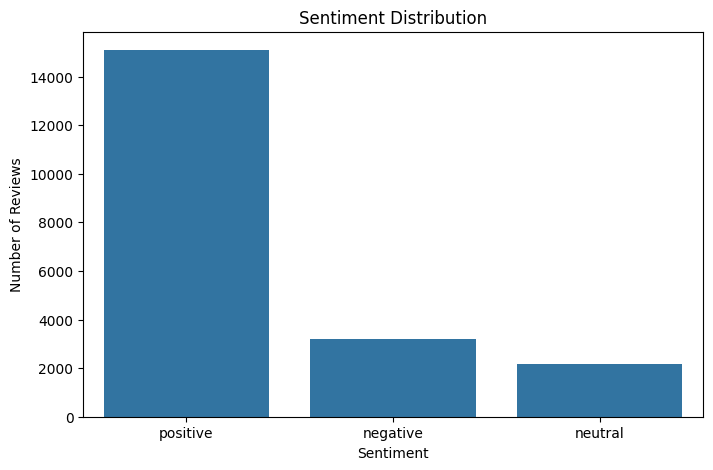

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("/content/tripadvisor_hotel_reviews.csv")

# Convert Rating → Sentiment
def map_sentiment(r):
    if r <= 2:
        return "negative"
    elif r == 3:
        return "neutral"
    else:
        return "positive"

df['sentiment'] = df['Rating'].apply(map_sentiment)

# Create bar chart
sentiment_counts = df['sentiment'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


In [ ]:
aspect_keywords = {
    "room": ["room", "bed", "suite", "accommodation", "bedsheet", "bedroom", "bathroom"],
    "food": ["food", "breakfast", "restaurant", "dinner", "lunch", "cuisine", "meal"],
    "service": ["service", "staff", "reception", "manager", "waiter", "attendant", "polite", "rude"],
    "cleanliness": ["clean", "dirty", "hygiene", "cleanliness", "stains", "tidy", "unclean"],
    "location": ["location", "area", "distance", "near", "close", "walk", "transport"]
}
aspect_keywords_lower = {a: [kw.lower() for kw in kws] for a, kws in aspect_keywords.items()}


In [ ]:
from transformers import pipeline

distilbert_pipe = pipeline('sentiment-analysis')

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


In [ ]:
from nltk.tokenize import sent_tokenize
import nltk

try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')

try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')


aspect_keywords = {
    "room": ["room", "bed", "suite", "accommodation", "bedsheet", "bedroom", "bathroom"],
    "food": ["food", "breakfast", "restaurant", "dinner", "lunch", "cuisine", "meal"],
    "service": ["service", "staff", "reception", "manager", "waiter", "attendant", "polite", "rude"],
    "cleanliness": ["clean", "dirty", "hygiene", "cleanliness", "stains", "tidy", "unclean"],
    "location": ["location", "area", "distance", "near", "close", "walk", "transport"]
}
aspect_keywords_lower = {a: [kw.lower() for kw in kws] for a, kws in aspect_keywords.items()}


In [ ]:
def detect_aspects(review_text):
    sentences = sent_tokenize(str(review_text))
    found = {}
    for s in sentences:
        s_low = s.lower()
        for aspect, kws in aspect_keywords_lower.items():
            if any(kw in s_low for kw in kws):
                found.setdefault(aspect, []).append(s.strip())
    return found

In [ ]:
review_text = """
The room was clean and spacious. The staff were polite and friendly.
The food was cold and tasted bad. The location was close to the beach.
"""

output = detect_aspects(review_text)


import pprint
pprint.pprint(output)

{'cleanliness': ['The room was clean and spacious.'],
 'food': ['The food was cold and tasted bad.'],
 'location': ['The location was close to the beach.'],
 'room': ['The room was clean and spacious.'],
 'service': ['The staff were polite and friendly.']}


In [ ]:
def aggregate_sentiments(sent_list):
    if not sent_list:
        return None
    total = 0.0
    for item in sent_list:
        label = item['label'].upper()
        score = float(item.get('score', 0.0))
        if label == 'POSITIVE':
            total += score
        elif label == 'NEGATIVE':
            total -= score

    if total > 0.15:
        return 'positive'
    elif total < -0.15:
        return 'negative'
    else:
        return 'neutral'

In [ ]:
detected_aspects = detect_aspects(review_text)
print("Detected Aspects and Sentences:")
pprint.pprint(detected_aspects)
print("\n" + "-"*60 + "\n")

aspect_sentiments = {}
for aspect, sentences in detected_aspects.items():
    results = distilbert_pipe(sentences)
    aspect_sentiments[aspect] = aggregate_sentiments(results)

print("Final Aspect Sentiments:")
pprint.pprint(aspect_sentiments)

Detected Aspects and Sentences:
{'cleanliness': ['The room was clean and spacious.'],
 'food': ['The food was cold and tasted bad.'],
 'location': ['The location was close to the beach.'],
 'room': ['The room was clean and spacious.'],
 'service': ['The staff were polite and friendly.']}

------------------------------------------------------------

Final Aspect Sentiments:
{'cleanliness': 'positive',
 'food': 'negative',
 'location': 'positive',
 'room': 'positive',
 'service': 'positive'}


In [ ]:
roberta_pipe = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest")


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


vocab.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Device set to use cuda:0


In [ ]:
review_text = """
The room was clean and spacious. The staff were polite and friendly.
The food was cold and tasted bad. The location was close to the beach.
"""

detected_aspects = detect_aspects(review_text)

print("Detected Aspects and Sentences:")
pprint.pprint(detected_aspects)
print("\n" + "-"*60 + "\n")

aspect_sentiments_comparison = {}

for aspect, sentences in detected_aspects.items():
    print(f"Aspect: {aspect}")

    # DistilBERT results
    distilbert_results = distilbert_pipe(sentences)
    distilbert_summary = aggregate_sentiments(distilbert_results)

    # RoBERTa results
    roberta_results = roberta_pipe(sentences)
    roberta_summary = aggregate_sentiments(roberta_results)

    aspect_sentiments_comparison[aspect] = {
        "DistilBERT": distilbert_summary,
        "RoBERTa": roberta_summary
    }

    print(f"DistilBERT ➤ {distilbert_summary}")
    print(f"RoBERTa   ➤ {roberta_summary}")
    print("-"*40)

print("\n Final Aspect-wise Comparison:")
pprint.pprint(aspect_sentiments_comparison)

Detected Aspects and Sentences:
{'cleanliness': ['The room was clean and spacious.'],
 'food': ['The food was cold and tasted bad.'],
 'location': ['The location was close to the beach.'],
 'room': ['The room was clean and spacious.'],
 'service': ['The staff were polite and friendly.']}

------------------------------------------------------------

Aspect: room
DistilBERT ➤ positive
RoBERTa   ➤ positive
----------------------------------------
Aspect: cleanliness
DistilBERT ➤ positive
RoBERTa   ➤ positive
----------------------------------------
Aspect: service
DistilBERT ➤ positive
RoBERTa   ➤ positive
----------------------------------------
Aspect: food
DistilBERT ➤ negative
RoBERTa   ➤ negative
----------------------------------------
Aspect: location
DistilBERT ➤ positive
RoBERTa   ➤ neutral
----------------------------------------

 Final Aspect-wise Comparison:
{'cleanliness': {'DistilBERT': 'positive', 'RoBERTa': 'positive'},
 'food': {'DistilBERT': 'negative', 'RoBERTa': 'neg

In [ ]:
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [ ]:
#Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_tfidf, y_train)


y_pred = lr.predict(X_test_tfidf)

from sklearn.metrics import accuracy_score
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))


Logistic Regression Accuracy: 0.8111298482293423
              precision    recall  f1-score   support

           0       0.87      0.64      0.74       115
           1       1.00      0.01      0.03        71
           2       0.80      1.00      0.89       407

    accuracy                           0.81       593
   macro avg       0.89      0.55      0.55       593
weighted avg       0.84      0.81      0.76       593



In [ ]:
from sklearn.metrics import accuracy_score
from tqdm import tqdm


sample_reviews = X_test.sample(200, random_state=42)
true_labels = y_test.loc[sample_reviews.index]

#DistilBERT
distilbert_preds = []
for review in tqdm(sample_reviews):
    result = distilbert_pipe(review[:512])[0]['label']  # truncate to 512 chars
    if result == 'POSITIVE':
        distilbert_preds.append(2)
    elif result == 'NEGATIVE':
        distilbert_preds.append(0)
    else:
        distilbert_preds.append(1)
print("DistilBERT Accuracy:", accuracy_score(true_labels, distilbert_preds))



100%|██████████| 200/200 [00:01<00:00, 194.28it/s]

DistilBERT Accuracy: 0.735


In [ ]:
label_map = {"negative": 0, "neutral": 1, "positive": 2}
df["label"] = df["sentiment"].map(label_map).astype(int)


In [ ]:
from transformers import RobertaTokenizer, RobertaForSequenceClassification, Trainer, TrainingArguments
from sklearn.model_selection import train_test_split
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


tokenizer = RobertaTokenizer.from_pretrained("roberta-base")
model = RobertaForSequenceClassification.from_pretrained("roberta-base", num_labels=3)

label_map = {"negative": 0, "neutral": 1, "positive": 2}
df["label"] = df["sentiment"].map(label_map).astype(int)

# train/test split
train_texts, val_texts, train_labels, val_labels = train_test_split(
    df["Review"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]


def encode_batch(texts, labels):
    encodings = tokenizer(
        list(texts),
        truncation=True,
        padding=True,
        max_length=128
    )
    encodings["labels"] = list(map(int, labels))   # <-- FIXED
    return Dataset.from_dict(encodings)


train_dataset = encode_batch(train_texts, train_labels)
val_dataset = encode_batch(val_texts, val_labels)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average='weighted'),
        "recall": recall_score(labels, preds, average='weighted'),
        "f1": f1_score(labels, preds, average='weighted')
    }


training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_dir="./logs",
)


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

trainer.train()


metrics = trainer.evaluate()
print(metrics)

#accuracy
print("Accuracy:", metrics["eval_accuracy"])


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.375900,0.352267,0.859478,0.878116,0.859478,0.867407
2,0.339200,0.401504,0.877287,0.865220,0.877287,0.868859
3,0.300700,0.445011,0.880459,0.878239,0.880459,0.879206


{'eval_loss': 0.4450114667415619, 'eval_accuracy': 0.8804586484508417, 'eval_precision': 0.8782394759345121, 'eval_recall': 0.8804586484508417, 'eval_f1': 0.879206065613131, 'eval_runtime': 27.8519, 'eval_samples_per_second': 147.171, 'eval_steps_per_second': 18.419, 'epoch': 3.0}
Accuracy: 0.8804586484508417


In [ ]:
import pandas as pd

accuracy_scores = {
    'Logistic Regression':  0.86,
    'DistilBERT': 0.785,
    'Fine-tuned RoBERTa': 8804586484508417
}

accuracy_df = pd.DataFrame(accuracy_scores.items(), columns=['Model', 'Accuracy'])
accuracy_df = accuracy_df.set_index('Model')

print("Accuracy scores per model:")
print(accuracy_df)


Accuracy scores per model:
                         Accuracy
Model                            
Logistic Regression  8.600000e-01
DistilBERT           7.850000e-01
Fine-tuned RoBERTa   8.804586e+15


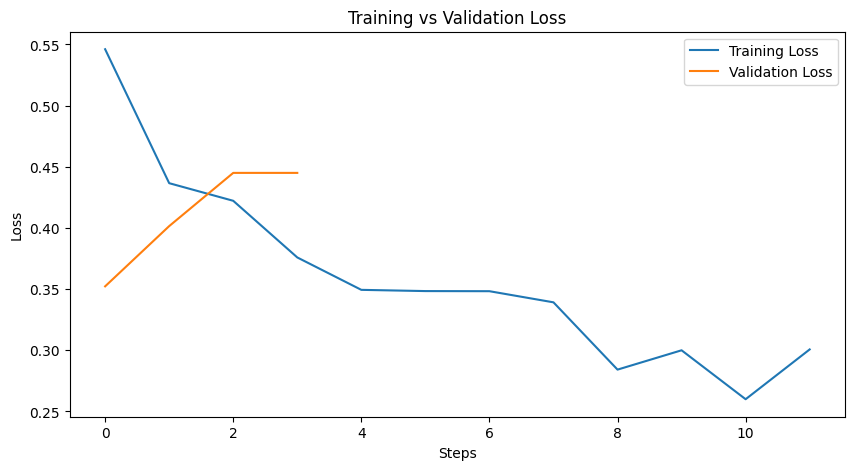

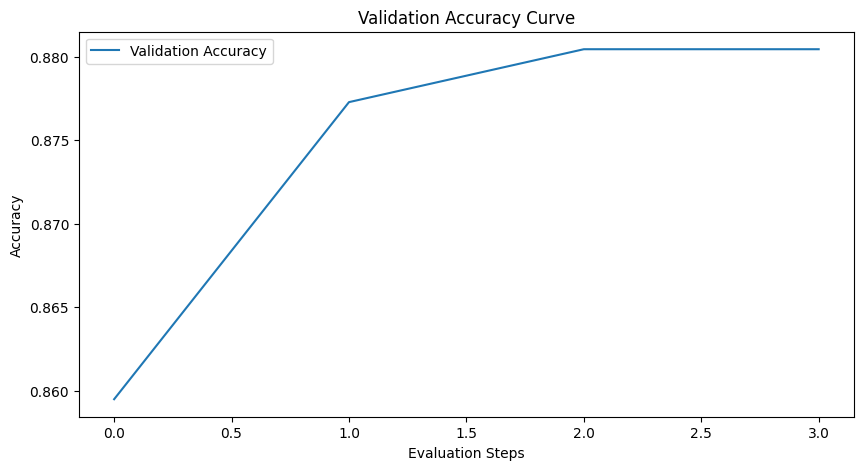

In [ ]:
import matplotlib.pyplot as plt

training_logs = trainer.state.log_history

# Extract accuracy and loss values from logs
train_loss = [x["loss"] for x in training_logs if "loss" in x.keys()]
eval_loss = [x["eval_loss"] for x in training_logs if "eval_loss" in x.keys()]
eval_accuracy = [x["eval_accuracy"] for x in training_logs if "eval_accuracy" in x.keys()]

# Plot Loss Curve
plt.figure(figsize=(10,5))
plt.plot(train_loss, label="Training Loss")
plt.plot(eval_loss, label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot Accuracy Curve
plt.figure(figsize=(10,5))
plt.plot(eval_accuracy, label="Validation Accuracy")
plt.title("Validation Accuracy Curve")
plt.xlabel("Evaluation Steps")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


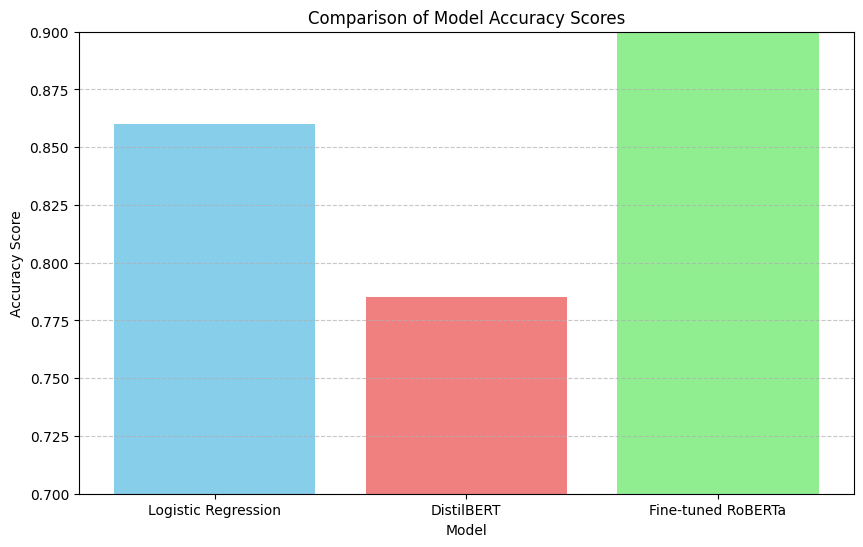

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(accuracy_df.index, accuracy_df['Accuracy'], color=['skyblue', 'lightcoral', 'lightgreen'])
plt.xlabel('Model')
plt.ylabel('Accuracy Score')
plt.title('Comparison of Model Accuracy Scores')
plt.ylim(0.7, 0.9)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [ ]:
!pip install gradio transformers nltk --quiet

import gradio as gr
from transformers import pipeline
from nltk.tokenize import sent_tokenize
import nltk


try:
    nltk.data.find("tokenizers/punkt")
except:
    nltk.download("punkt")

try:
    nltk.data.find("tokenizers/punkt_tab")
except:
    nltk.download("punkt_tab")


distilbert_pipe = pipeline("sentiment-analysis")
roberta_pipe = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment")


aspect_keywords = {
    "room": ["room", "bed", "suite", "accommodation", "bedsheet", "bedroom", "bathroom"],
    "food": ["food", "breakfast", "restaurant", "dinner", "lunch", "cuisine", "meal"],
    "service": ["service", "staff", "reception", "manager", "waiter", "attendant", "polite", "rude"],
    "cleanliness": ["clean", "dirty", "hygiene", "cleanliness", "stains", "tidy", "unclean"],
    "location": ["location", "area", "distance", "near", "close", "walk", "transport"]
}
aspect_keywords_lower = {a: [kw.lower() for kw in kws] for a, kws in aspect_keywords.items()}


def detect_aspects(review_text):
    sentences = sent_tokenize(str(review_text))
    found = {}
    for s in sentences:
        s_low = s.lower()
        for aspect, kws in aspect_keywords_lower.items():
            if any(kw in s_low for kw in kws):
                found.setdefault(aspect, []).append(s.strip())
    return found


def normalize_label(label):
    """Convert LABEL_0/LABEL_1 → positive/negative"""
    label = label.upper()
    if label in ["POSITIVE", "LABEL_2"]:
        return "positive"
    if label in ["NEGATIVE", "LABEL_0"]:
        return "negative"
    return "neutral"

def aggregate_sentiments(preds):
    if not preds:
        return "neutral"
    pos = sum(item["score"] for item in preds if normalize_label(item["label"]) == "positive")
    neg = sum(item["score"] for item in preds if normalize_label(item["label"]) == "negative")
    if pos - neg > 0.15:
        return "positive"
    elif neg - pos > 0.15:
        return "negative"
    else:
        return "neutral"


def analyze_review(review, model_choice):
    if not review.strip():
        return {"error":"Empty review"}, "N/A"

    try:
        detected = detect_aspects(review)
        pipe = distilbert_pipe if model_choice == "DistilBERT" else roberta_pipe

        output = {}
        for aspect, sents in detected.items():
            preds = pipe(sents)
            output[aspect] = aggregate_sentiments(preds)

        overall = normalize_label(pipe(review[:512])[0]["label"])

        return output, overall

    except Exception as e:
        return {"error": str(e)}, "Error"


with gr.Blocks(css="""
    .gradio-container {background-color: #1e1e1e;}
    h1, h2, h3, p {color: #ffffff !important;}
    .output-box {border-radius: 12px; padding: 15px; background:#2a2a2a;}
    .gr-input {background:#2a2a2a !important; color:white !important;}
    .gr-text-input textarea {background:#2a2a2a !important; color:white !important;}
    .btn-analyze {background:#4CAF50 !important; color:white !important; border-radius:12px;}
""") as demo:

    gr.HTML("""
    <div style='text-align:center; padding:15px'>
        <h1 style='color:#4CAF50; font-size:32px;'>🏨 Aspect-Based Sentiment Analyzer</h1>
        <p style='font-size:16px; color:#cccccc'>
            Analyze hotel reviews with aspect-wise sentiment detection using modern NLP models.
        </p>
    </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            review_input = gr.Textbox(
                lines=6,
                label="📝 Enter Review",
                elem_classes="gr-input",
                placeholder="Write or paste a hotel review..."
            )

            model_choice = gr.Dropdown(
                ["DistilBERT", "RoBERTa"],
                label="🤖 Select Model",
                value="DistilBERT",
                elem_classes="gr-input"
            )

            btn = gr.Button("🔍 Analyze", elem_classes="btn-analyze")

        with gr.Column(scale=1):
            gr.HTML("""
            <div style='padding:10px; border-radius:12px; background:#2d2d2d;'>
                <h3 style='color:#4CAF50;'>📊 Aspect-wise Sentiment</h3>
            </div>
            """)

            aspect_output = gr.JSON(label="", elem_classes="output-box")

            gr.HTML("""
            <div style='padding:10px; margin-top:20px; border-radius:12px; background:#2d2d2d;'>
                <h3 style='color:#4CAF50;'>🌟 Overall Review Sentiment</h3>
            </div>
            """)

            overall_output = gr.Textbox(label="", elem_classes="output-box")

    btn.click(analyze_review, [review_input, model_choice], [aspect_output, overall_output])

demo.launch()

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
Device set to use cuda:0
Device set to use cuda:0


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://36644158877390209a.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


#Interface

In [ ]:
!pip install streamlit pyngrok==4.1.1


In [ ]:
from pyngrok import ngrok
ngrok.set_auth_token("35YxG66crVTtRU89L3eBMYJpckK_7W4r98qhckoQ8Er9zA5rg")


In [ ]:
from pyngrok import ngrok
import subprocess
import os, signal

ngrok.kill()

!kill -9 $(lsof -t -i:8501) 2>/dev/null


In [ ]:
!npm install -g localtunnel


In [ ]:
!pip install streamlit -q
!wget -q https://bin.equinox.io/c/bNyj1mQVY4c/ngrok-v3-stable-linux-amd64.tgz
!tar -xvzf ngrok-v3-stable-linux-amd64.tgz


In [ ]:
NGROK_TOKEN = "35YxG66crVTtRU89L3eBMYJpckK_7W4r98qhckoQ8Er9zA5rg"
!./ngrok config add-authtoken $NGROK_TOKEN


In [ ]:
%%writefile hotel_review_app.py
import streamlit as st
from transformers import pipeline
import nltk
import re
import pandas as pd
from datetime import datetime


def safe_sentence_tokenize(text):

    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in sentences if len(s.strip()) > 1]


# Streamlit UI Configuration

st.set_page_config(
    page_title="Review Analyzer",
    layout="wide",
    page_icon="📝"
)


st.markdown("""
<style>
:root{
  --bg:#fbf9ff;
  --card:#ffffff;
  --muted:#7d7d7d;
  --accent1:#d6c7ff;
  --accent2:#ffe7f2;
  --accent3:#c8f7e5;
  --accent4:#ffdca8;
}
body { background: var(--bg); }
.header { text-align:center; padding:20px 0; }
.title { font-size:34px; color:#6A5ACD; font-weight:800; margin-bottom:4px; }
.subtitle { color:var(--muted); margin-bottom:18px; }
.input-card {
  background: var(--card);
  border-radius:16px;
  padding:18px;
  box-shadow: 0 6px 18px rgba(110,90,200,0.08);
  border: 1px solid #f1ecff;
}
.aspect-card {
  background: var(--card);
  border-radius:12px;
  padding:14px;
  margin-bottom:10px;
  border-left:8px solid #E6D8FF;
  box-shadow: 0 4px 10px rgba(120,100,170,0.04);
}
.badge {
  display:inline-block;
  padding:6px 12px;
  border-radius:999px;
  font-weight:700;
  color:white;
}
.pos { background:#7ED957; }
.neg { background:#FF8A80; }
.neu { background:#BDBDBD; }
.small { font-size:13px; color:var(--muted); }
.footer { color: var(--muted); font-size:13px; margin-top:10px; }
</style>
""", unsafe_allow_html=True)

st.markdown(
    '<div class="header">'
    '<div class="title">📝 Review Analyzer</div>'
    '<div class="subtitle">Aspect-Based Sentiment & Star Rating Predictor</div>'
    '</div>',
    unsafe_allow_html=True
)


@st.cache_resource(show_spinner=True)
def load_pipeline():
    return pipeline("sentiment-analysis")

sent_pipe = load_pipeline()


ASPECT_KEYWORDS = {
    "Room": ["room", "bed", "suite", "ac", "comfortable"],
    "Food": ["food", "breakfast", "restaurant", "meal"],
    "Service": ["service", "staff", "reception", "manager"],
    "Cleanliness": ["clean", "dirty", "hygiene"],
    "Location": ["location", "area", "near", "distance"],
    "Price": ["price", "cost", "expensive", "cheap"]
}

def detect_aspects(text):
    sentences = safe_sentence_tokenize(text)
    found = {}

    for s in sentences:
        s_low = s.lower()
        for aspect, kws in ASPECT_KEYWORDS_LOWER.items():
            if any(kw in s_low for kw in kws):
                found.setdefault(aspect, []).append(s.strip())

    return found

def normalize_label(label):
    L = label.upper()
    if L in ("POSITIVE", "LABEL_2"):
        return "positive"
    if L in ("NEGATIVE", "LABEL_0"):
        return "negative"
    return "neutral"

def aggregate_sentiment(preds):
    pos = sum(p["score"] for p in preds if normalize_label(p["label"])=="positive")
    neg = sum(p["score"] for p in preds if normalize_label(p["label"])=="negative")

    score = pos - neg
    if score > 0.15: tag="positive"
    elif score < -0.15: tag="negative"
    else: tag="neutral"

    return tag, score

def predict_star(overall_score, aspect_scores):
    base = (overall_score + 1) * 2
    pos_aspects = sum(1 for s in aspect_scores.values() if s > 0.2)
    neg_aspects = sum(1 for s in aspect_scores.values() if s < -0.2)
    stars = base + pos_aspects*0.2 - neg_aspects*0.3
    stars = int(round(min(4, max(0, stars)))) + 1
    return max(1, min(5, stars))

# UI Layout

col1, col2 = st.columns([1.1, 1])

with col1:
    st.markdown('<div class="input-card">', unsafe_allow_html=True)
    st.subheader("✍ Enter a review")
    review_text = st.text_area("", height=200)
    analyze = st.button("Analyze Review", type="primary")
    st.markdown("</div>", unsafe_allow_html=True)


if analyze:
    if not review_text.strip():
        st.warning("Please enter a review before analyzing.")
    else:
        with st.spinner("Analyzing..."):

            # Overall sentiment
            overall_pred = sent_pipe(review_text[:800])[0]
            tag = normalize_label(overall_pred["label"])
            score = overall_pred["score"] if tag=="positive" else -overall_pred["score"]

            # Aspect extraction
            aspect_sents = detect_aspects(review_text)
            aspect_results = {}
            numeric_scores = {}

            for asp in ASPECT_KEYWORDS:
                sents = aspect_sents.get(asp, [])
                if sents:
                    preds = sent_pipe(sents)
                    a_tag, a_score = aggregate_sentiment(preds)
                else:
                    a_tag, a_score = "neutral", 0.0

                aspect_results[asp] = {"tag":a_tag, "score":a_score, "examples":sents[:3]}
                numeric_scores[asp] = a_score

            stars = predict_star(score, numeric_scores)


        st.markdown("### 🔎 Summary")
        st.write(f"**Overall Sentiment:** {tag.capitalize()} (Confidence: {round(abs(score),3)})")
        st.write(f"**Predicted Rating:** {'⭐'*stars}  ({stars}/5)")

        # Aspect Section
        st.markdown("### 🧭 Aspect Sentiments")
        for asp, info in aspect_results.items():
            badge = "pos" if info["tag"]=="positive" else "neg" if info["tag"]=="negative" else "neu"

            st.markdown(
                f"""
                <div class="aspect-card">
                    <h4>{asp}</h4>
                    <div class="badge {badge}">{info['tag'].capitalize()}</div>
                    <div class="small">Score: {round(info['score'],3)}</div>
                """,
                unsafe_allow_html=True
            )

            if info["examples"]:
                for ex in info["examples"]:
                    st.markdown(f"<div style='background:#fbf7ff; padding:8px; margin:6px; border-radius:8px'>{ex}</div>", unsafe_allow_html=True)
            else:
                st.markdown("<div class='small'>No sentences detected for this aspect.</div>", unsafe_allow_html=True)

            st.markdown("</div>", unsafe_allow_html=True)


        st.markdown("### 💾 Save Result")

        row = {
            "timestamp": datetime.utcnow().isoformat(),
            "review": review_text,
            "overall_sentiment": tag,
            "overall_confidence": float(abs(score)),
            "star_rating": stars
        }
        for a, s in numeric_scores.items():
            row[f"aspect_{a.lower()}"] = float(s)

        df = pd.DataFrame([row])
        csv_bytes = df.to_csv(index=False).encode("utf-8")

        st.download_button(
            "Download CSV",
            data=csv_bytes,
            file_name="review_analysis.csv",
            mime="text/csv"
        )

        st.markdown("<div class='footer'>Analysis complete!</div>", unsafe_allow_html=True)


In [ ]:
!pip install streamlit pyngrok==4.1.1

rom pyngrok import ngrok
ngrok.set_auth_token("35YxG66crVTtRU89L3eBMYJpckK_7W4r98qhckoQ8Er9zA5rg")

from pyngrok import ngrok
import subprocess
import os, signal

ngrok.kill()

!kill -9 $(lsof -t -i:8501) 2>/dev/null

!npm install -g localtunnel

!pip install streamlit -q
!wget -q https://bin.equinox.io/c/bNyj1mQVY4c/ngrok-v3-stable-linux-amd64.tgz
!tar -xvzf ngrok-v3-stable-linux-amd64.tgz


NGROK_TOKEN = "35YxG66crVTtRU89L3eBMYJpckK_7W4r98qhckoQ8Er9zA5rg"
!./ngrok config add-authtoken $NGROK_TOKEN

%%writefile hotel_review_app.py
import streamlit as st
from transformers import pipeline
import nltk
import re
import pandas as pd
from datetime import datetime


def safe_sentence_tokenize(text):

    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in sentences if len(s.strip()) > 1]


# Streamlit UI Configuration

st.set_page_config(
    page_title="Review Analyzer",
    layout="wide",
    page_icon="📝"
)


st.markdown("""
<style>
:root{
  --bg:#fbf9ff;
  --card:#ffffff;
  --muted:#7d7d7d;
  --accent1:#d6c7ff;
  --accent2:#ffe7f2;
  --accent3:#c8f7e5;
  --accent4:#ffdca8;
}
body { background: var(--bg); }
.header { text-align:center; padding:20px 0; }
.title { font-size:34px; color:#6A5ACD; font-weight:800; margin-bottom:4px; }
.subtitle { color:var(--muted); margin-bottom:18px; }
.input-card {
  background: var(--card);
  border-radius:16px;
  padding:18px;
  box-shadow: 0 6px 18px rgba(110,90,200,0.08);
  border: 1px solid #f1ecff;
}
.aspect-card {
  background: var(--card);
  border-radius:12px;
  padding:14px;
  margin-bottom:10px;
  border-left:8px solid #E6D8FF;
  box-shadow: 0 4px 10px rgba(120,100,170,0.04);
}
.badge {
  display:inline-block;
  padding:6px 12px;
  border-radius:999px;
  font-weight:700;
  color:white;
}
.pos { background:#7ED957; }
.neg { background:#FF8A80; }
.neu { background:#BDBDBD; }
.small { font-size:13px; color:var(--muted); }
.footer { color: var(--muted); font-size:13px; margin-top:10px; }
</style>
""", unsafe_allow_html=True)

st.markdown(
    '<div class="header">'
    '<div class="title">📝 Review Analyzer</div>'
    '<div class="subtitle">Aspect-Based Sentiment & Star Rating Predictor</div>'
    '</div>',
    unsafe_allow_html=True
)


@st.cache_resource(show_spinner=True)
def load_pipeline():
    return pipeline("sentiment-analysis")

sent_pipe = load_pipeline()


ASPECT_KEYWORDS = {
    "Room": ["room", "bed", "suite", "ac", "comfortable"],
    "Food": ["food", "breakfast", "restaurant", "meal"],
    "Service": ["service", "staff", "reception", "manager"],
    "Cleanliness": ["clean", "dirty", "hygiene"],
    "Location": ["location", "area", "near", "distance"],
    "Price": ["price", "cost", "expensive", "cheap"]
}

def detect_aspects(text):
    sentences = safe_sentence_tokenize(text)
    found = {}

    for s in sentences:
        s_low = s.lower()
        for aspect, kws in ASPECT_KEYWORDS_LOWER.items():
            if any(kw in s_low for kw in kws):
                found.setdefault(aspect, []).append(s.strip())

    return found

def normalize_label(label):
    L = label.upper()
    if L in ("POSITIVE", "LABEL_2"):
        return "positive"
    if L in ("NEGATIVE", "LABEL_0"):
        return "negative"
    return "neutral"

def aggregate_sentiment(preds):
    pos = sum(p["score"] for p in preds if normalize_label(p["label"])=="positive")
    neg = sum(p["score"] for p in preds if normalize_label(p["label"])=="negative")

    score = pos - neg
    if score > 0.15: tag="positive"
    elif score < -0.15: tag="negative"
    else: tag="neutral"

    return tag, score

def predict_star(overall_score, aspect_scores):
    base = (overall_score + 1) * 2
    pos_aspects = sum(1 for s in aspect_scores.values() if s > 0.2)
    neg_aspects = sum(1 for s in aspect_scores.values() if s < -0.2)
    stars = base + pos_aspects*0.2 - neg_aspects*0.3
    stars = int(round(min(4, max(0, stars)))) + 1
    return max(1, min(5, stars))

# UI Layout

col1, col2 = st.columns([1.1, 1])

with col1:
    st.markdown('<div class="input-card">', unsafe_allow_html=True)
    st.subheader("✍ Enter a review")
    review_text = st.text_area("", height=200)
    analyze = st.button("Analyze Review", type="primary")
    st.markdown("</div>", unsafe_allow_html=True)


if analyze:
    if not review_text.strip():
        st.warning("Please enter a review before analyzing.")
    else:
        with st.spinner("Analyzing..."):

            # Overall sentiment
            overall_pred = sent_pipe(review_text[:800])[0]
            tag = normalize_label(overall_pred["label"])
            score = overall_pred["score"] if tag=="positive" else -overall_pred["score"]

            # Aspect extraction
            aspect_sents = detect_aspects(review_text)
            aspect_results = {}
            numeric_scores = {}

            for asp in ASPECT_KEYWORDS:
                sents = aspect_sents.get(asp, [])
                if sents:
                    preds = sent_pipe(sents)
                    a_tag, a_score = aggregate_sentiment(preds)
                else:
                    a_tag, a_score = "neutral", 0.0

                aspect_results[asp] = {"tag":a_tag, "score":a_score, "examples":sents[:3]}
                numeric_scores[asp] = a_score

            stars = predict_star(score, numeric_scores)


        st.markdown("### 🔎 Summary")
        st.write(f"**Overall Sentiment:** {tag.capitalize()} (Confidence: {round(abs(score),3)})")
        st.write(f"**Predicted Rating:** {'⭐'*stars}  ({stars}/5)")

        # Aspect Section
        st.markdown("### 🧭 Aspect Sentiments")
        for asp, info in aspect_results.items():
            badge = "pos" if info["tag"]=="positive" else "neg" if info["tag"]=="negative" else "neu"

            st.markdown(
                f"""
                <div class="aspect-card">
                    <h4>{asp}</h4>
                    <div class="badge {badge}">{info['tag'].capitalize()}</div>
                    <div class="small">Score: {round(info['score'],3)}</div>
                """,
                unsafe_allow_html=True
            )

            if info["examples"]:
                for ex in info["examples"]:
                    st.markdown(f"<div style='background:#fbf7ff; padding:8px; margin:6px; border-radius:8px'>{ex}</div>", unsafe_allow_html=True)
            else:
                st.markdown("<div class='small'>No sentences detected for this aspect.</div>", unsafe_allow_html=True)

            st.markdown("</div>", unsafe_allow_html=True)


        st.markdown("### 💾 Save Result")

        row = {
            "timestamp": datetime.utcnow().isoformat(),
            "review": review_text,
            "overall_sentiment": tag,
            "overall_confidence": float(abs(score)),
            "star_rating": stars
        }
        for a, s in numeric_scores.items():
            row[f"aspect_{a.lower()}"] = float(s)

        df = pd.DataFrame([row])
        csv_bytes = df.to_csv(index=False).encode("utf-8")

        st.download_button(
            "Download CSV",
            data=csv_bytes,
            file_name="review_analysis.csv",
            mime="text/csv"
        )

st.markdown("<div class='footer'>Analysis complete!</div>", unsafe_allow_html=True)

# Kill if any old processes
!kill -9 $(lsof -t -i:8501) 2>/dev/null

# Start Streamlit
import subprocess
streamlit_process = subprocess.Popen(
    ["streamlit", "run", "hotel_review_app.py", "--server.port=8501", "--server.address=0.0.0.0"]
)

# Kill if any old processes
!kill -9 $(lsof -t -i:8501) 2>/dev/null

# Start Streamlit
import subprocess
streamlit_process = subprocess.Popen(
    ["streamlit", "run", "hotel_review_app.py", "--server.port=8501", "--server.address=0.0.0.0"]
)

!./ngrok http 8501 --log=stdout

In [ ]:
# Kill if any old processes
!kill -9 $(lsof -t -i:8501) 2>/dev/null

# Start Streamlit
import subprocess
streamlit_process = subprocess.Popen(
    ["streamlit", "run", "hotel_review_app.py", "--server.port=8501", "--server.address=0.0.0.0"]
)

!./ngrok http 8501 --log=stdout

In [ ]:
!./ngrok http 8501 --log=stdout


INFO[11-19|05:57:01] no configuration paths supplied 
WARN[11-19|05:57:01] ngrok config file found at legacy location, move to XDG location xdg_path=/root/.config/ngrok/ngrok.yml legacy_path=/root/.ngrok2/ngrok.yml
INFO[11-19|05:57:01] using configuration at default config path path=/root/.ngrok2/ngrok.yml
INFO[11-19|05:57:01] open config file                         path=/root/.ngrok2/ngrok.yml err=nil
t=2025-11-19T05:57:01+0000 lvl=info msg="FIPS 140 mode" enabled=false
t=2025-11-19T05:57:01+0000 lvl=info msg="starting web service" obj=web addr=127.0.0.1:4040 allow_hosts=[]
t=2025-11-19T05:57:01+0000 lvl=info msg="client session established" obj=tunnels.session
t=2025-11-19T05:57:01+0000 lvl=info msg="tunnel session started" obj=tunnels.session
t=2025-11-19T05:57:02+0000 lvl=info msg="started tunnel" obj=tunnels name=command_line addr=http://localhost:8501 url=https://impregnable-gus-unripely.ngrok-free.dev
t=2025-11-19T05:57:06+0000 lvl=warn msg="failed to check for update" obj=upda